# Data Exploration

### Loading Data

We will import kagglehub, and load the smaller csv training and testing files.

In [1]:
import sys

print(sys.executable)

c:\Users\madis\Documents\ADS2002-Melanoma\.venv\Scripts\python.exe


In [2]:
import kagglehub


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math as m

In [4]:
plt.rcParams["font.family"] = 'Verdana'

In [5]:
# Import code from module

from melanoma_detection.data import get_competition_file, load_train_metadata, load_test_metadata

In [ ]:
# load the training and testing sets of data


train_df = load_train_metadata()

test_df = load_test_metadata()




In [8]:
train_df

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0
...,...,...,...,...,...,...,...,...
33121,ISIC_9999134,IP_6526534,male,50.0,torso,unknown,benign,0
33122,ISIC_9999320,IP_3650745,male,65.0,torso,unknown,benign,0
33123,ISIC_9999515,IP_2026598,male,20.0,lower extremity,unknown,benign,0
33124,ISIC_9999666,IP_7702038,male,50.0,lower extremity,unknown,benign,0


### Data structure

Check the shape, columns, info, summary, number of duplicates, null entries, and datatypes.

In [9]:
train_df.head(8)

,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0
5,ISIC_0074311,IP_2950485,female,40.0,lower extremity,unknown,benign,0
6,ISIC_0074542,IP_4698288,male,25.0,lower extremity,unknown,benign,0
7,ISIC_0075663,IP_6017204,female,35.0,torso,unknown,benign,0


In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33126 entries, 0 to 33125
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   image_name                     33126 non-null  str    
 1   patient_id                     33126 non-null  str    
 2   sex                            33061 non-null  str    
 3   age_approx                     33058 non-null  float64
 4   anatom_site_general_challenge  32599 non-null  str    
 5   diagnosis                      33126 non-null  str    
 6   benign_malignant               33126 non-null  str    
 7   target                         33126 non-null  int64  
dtypes: float64(1), int64(1), str(6)
memory usage: 2.0 MB


In [11]:
train_df.describe()

,age_approx,target
count,33058.000000,33126.000000
mean,48.870016,0.017630
std,14.380360,0.131603
min,0.000000,0.000000
25%,40.000000,0.000000
50%,50.000000,0.000000
75%,60.000000,0.000000
max,90.000000,1.000000


Check all value counts

In [12]:
columns = ['sex','age_approx', 'anatom_site_general_challenge','diagnosis', 'benign_malignant','target']

for col in columns:

    counts = train_df[col].fillna('Missing').value_counts(dropna=False)

    proportions = train_df[col].fillna('Missing').value_counts(normalize=True) * 100
    print()
    print(f'+++++++++ {col} counts +++++++++')
    print(counts)

    print(f'+++++++++ {col} proportions +++++++++')
    print(proportions)


+++++++++ sex counts +++++++++
sex
male       17080
female     15981
Missing       65
Name: count, dtype: int64
+++++++++ sex proportions +++++++++
sex
male       51.560708
female     48.243072
Missing     0.196220
Name: proportion, dtype: float64

+++++++++ age_approx counts +++++++++
age_approx
45.0       4466
50.0       4270
55.0       3824
40.0       3576
60.0       3240
35.0       2850
65.0       2527
30.0       2358
70.0       1968
25.0       1544
75.0        981
20.0        655
80.0        419
85.0        149
15.0        132
90.0         80
Missing      68
10.0         17
0.0           2
Name: count, dtype: int64
+++++++++ age_approx proportions +++++++++
age_approx
45.0       13.481857
50.0       12.890177
55.0       11.543802
40.0       10.795146
60.0        9.780837
35.0        8.603514
65.0        7.628449
30.0        7.118276
70.0        5.940953
25.0        4.660991
75.0        2.961420
20.0        1.977299
80.0        1.264867
85.0        0.449798
15.0        0.398479
90

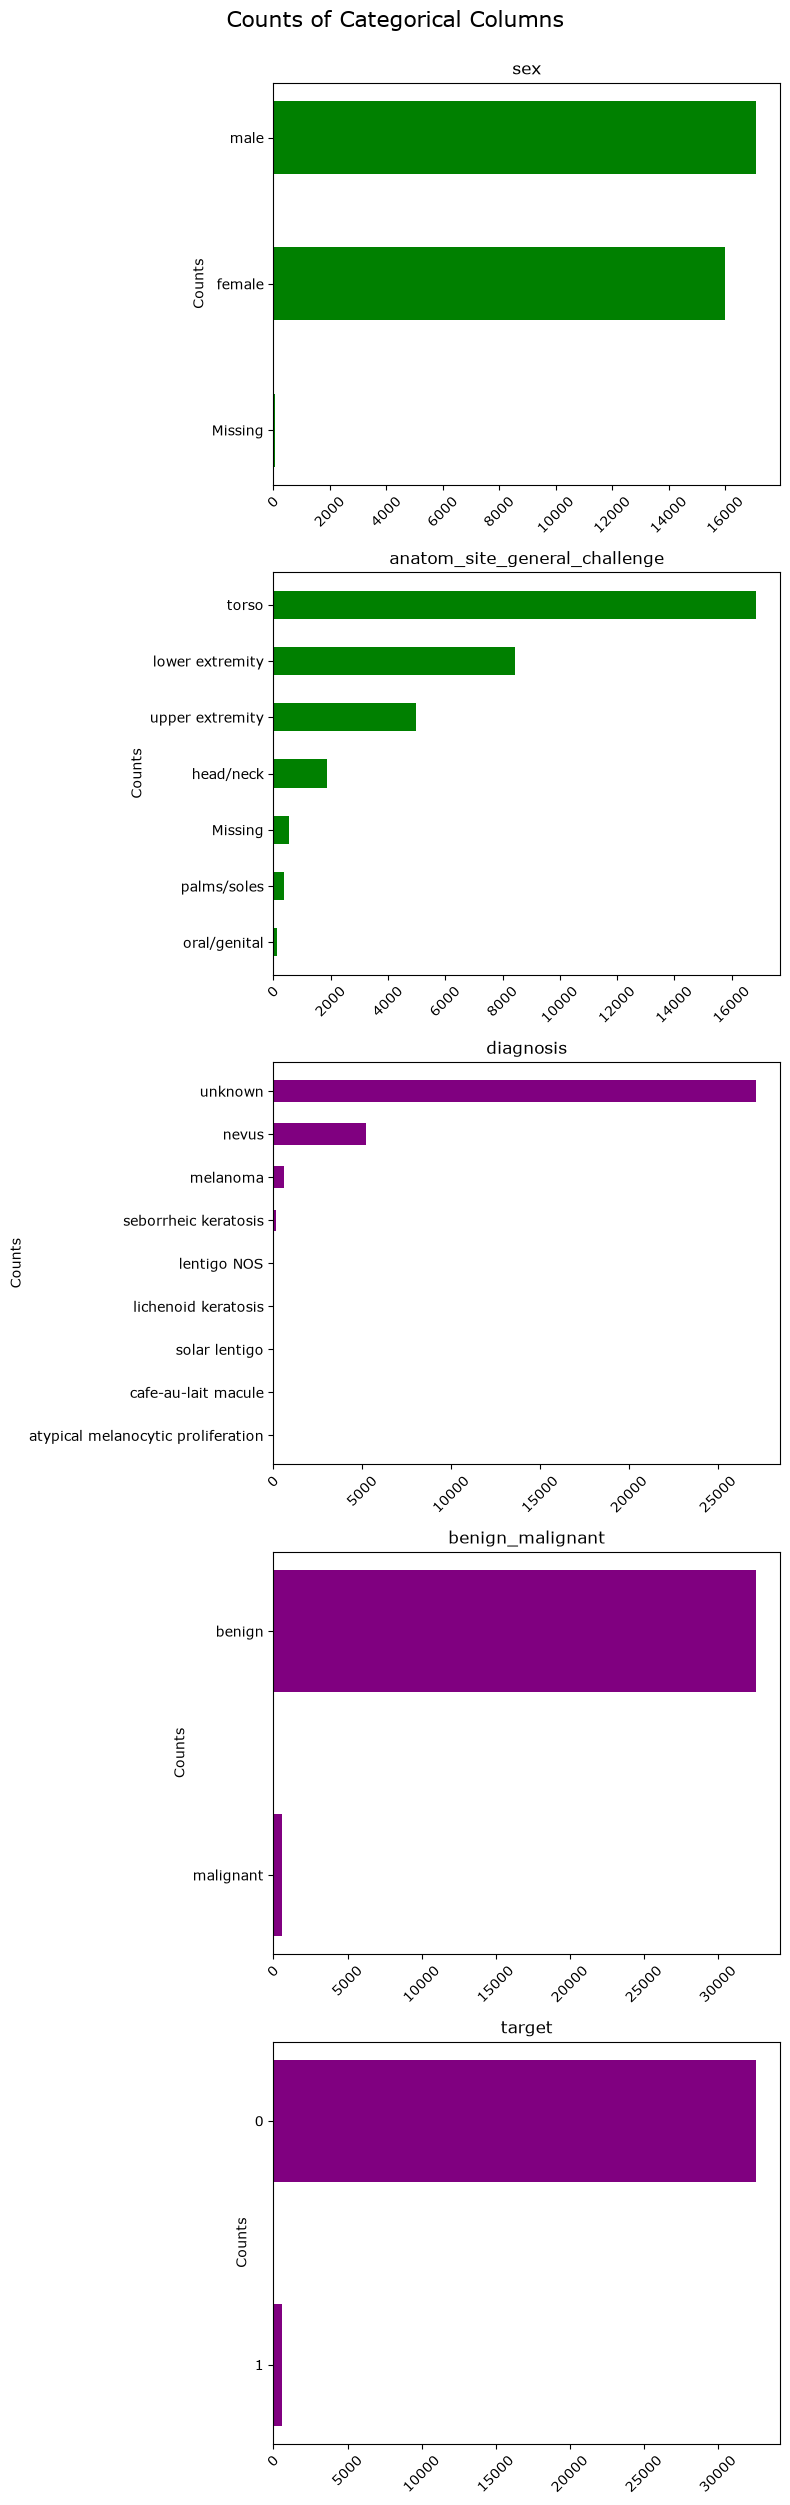

In [13]:
cat_cols = ['sex', 'anatom_site_general_challenge','diagnosis', 'benign_malignant','target']

colours = ['green','green','purple','purple','purple']
n_cols = 1
n_rows = m.ceil(len(cat_cols)/n_cols)



fig, axes = plt.subplots(n_rows, n_cols,figsize= (8, 5 * n_rows))

axes = axes.flatten()



for ax, col, c in zip(axes, cat_cols, colours):
    vals = train_df[col].fillna("Missing").astype(str).value_counts(dropna=False)


    ax.barh(vals.index, vals.values, height = 0.5, align='center', color = c)

    ax.set_title(col, fontweight=400)
    ax.set_ylabel("Counts")
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

    ax.invert_yaxis()

fig.suptitle("Counts of Categorical Columns", y = 1, size=16)
plt.subplots_adjust(hspace=0.9)
plt.tight_layout()



Findings:

